<a href="https://colab.research.google.com/github/Amanpreet0320/Data-Science-Projects/blob/main/PROJECT_3_Sales_Prediction_using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Sales Prediction using Python**
**Codealpha Data Science Internship**

**Name : Amanpreet Kaur**

**Domain : Data Science**

**Project 3 (Task:4) : Sales Prediction using Python**

# Project Objective

The objective of this project is to analyze sales data and build a model to predict sales based on advertising expenditure across different media channels.

The project includes data loading, data exploration, visualization, model development, evaluation, and interpretation of the results. The analysis helps understand how advertising investment influences sales and provides insights that can support better marketing decisions.

# 1. Import Required Libraries

This section imports the Python libraries required for data analysis, visualization, machine learning model development, and model evaluation.

- **Pandas** and **NumPy** are used for data manipulation and numerical operations.
- **Matplotlib** and **Seaborn** are used for data visualization.
- **Scikit-learn** provides tools for splitting the dataset, building regression models, and evaluating their performance.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 2. Dataset Loading

The dataset contains advertising expenditure across three media channels—TV, Radio, and Newspaper—along with the corresponding Sales.

The dataset is loaded into a Pandas DataFrame so that it can be explored, cleaned, visualized, and used for building regression models.

In [ ]:
df = pd.read_csv("Advertising.csv")

In [ ]:
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [ ]:
print("shape:", df.shape)

shape: (200, 5)


## Dataset Structure and Data Quality

The dataset is inspected to understand its structure, data types, and completeness. These checks help identify missing values and confirm that the variables are ready for further analysis and preprocessing.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


## Missing Value Check

The following check identifies the number of missing values in each column. This helps ensure that the dataset is complete before building the prediction models.

In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
TV,0
Radio,0
Newspaper,0
Sales,0


## Statistical Summary

The statistical summary provides key measures such as count, mean, standard deviation, minimum, maximum, and quartile values for the numerical variables. This helps us understand the distribution and range of the advertising and sales data.

In [ ]:
df.describe()

,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


## Data Cleaning

The dataset contains an unnecessary index column named `Unnamed: 0`, which was created when the CSV file was saved. This column does not contribute to sales prediction, so it is removed before continuing with the analysis.

In [ ]:
df = df.drop("Unnamed: 0", axis=1)
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


# 3. Exploratory Data Analysis (EDA)

## Distribution of Sales

This histogram shows the distribution of sales values in the dataset. It helps us understand the spread and concentration of sales and identify the overall pattern of the target variable.

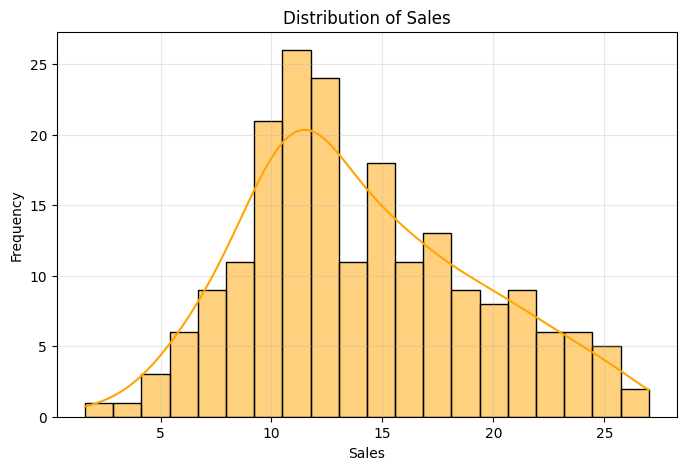

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Sales",
    bins=20,
    kde=True,
    color="orange"
)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.show()

## Relationship Between Advertising Expenditure and Product Sales

This analysis examines the relationship between advertising expenditure on TV, Radio, and Newspaper platforms and product sales. Scatter plots are used to identify patterns and understand how advertising investment is associated with sales performance.

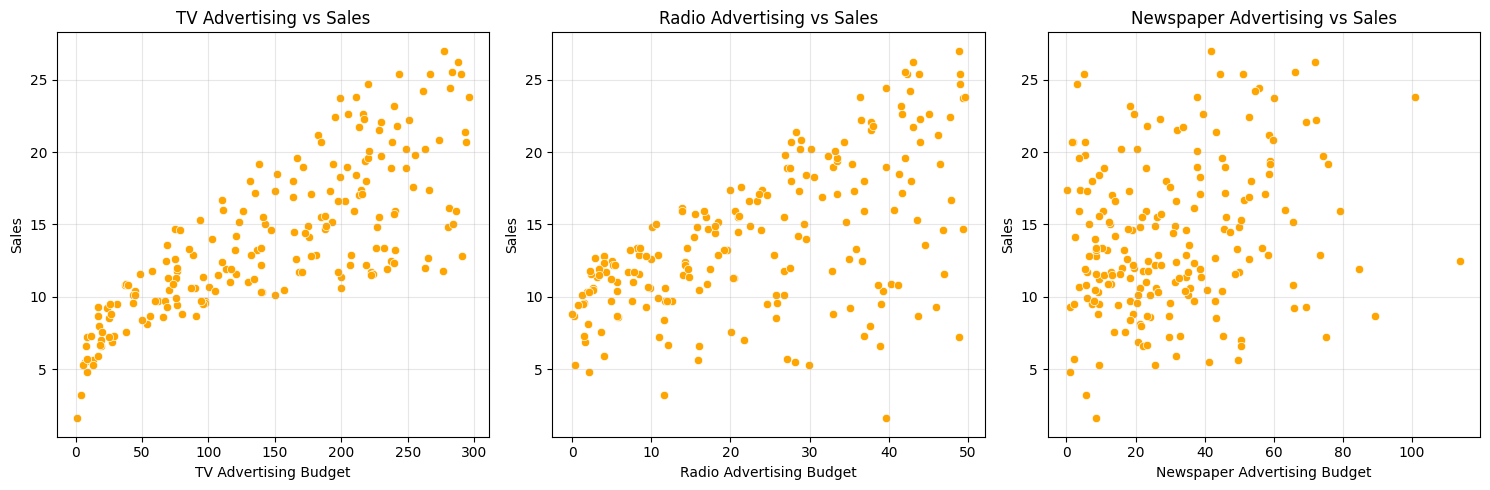

In [ ]:
plt.figure(figsize=(15, 5))

advertising_columns = ["TV", "Radio", "Newspaper"]

for i, col in enumerate(advertising_columns, 1):
    ax = plt.subplot(1, 3, i)

    sns.scatterplot(
        data=df,
        x=col,
        y="Sales",
        color="orange",
        ax=ax
    )

    ax.set_title(f"{col} Advertising vs Sales")
    ax.set_xlabel(f"{col} Advertising Budget")
    ax.set_ylabel("Sales")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Boxplots of Features

Boxplots are used to examine the distribution and spread of the numerical features in the dataset. They help identify the median, variability, and potential outliers in the advertising data.

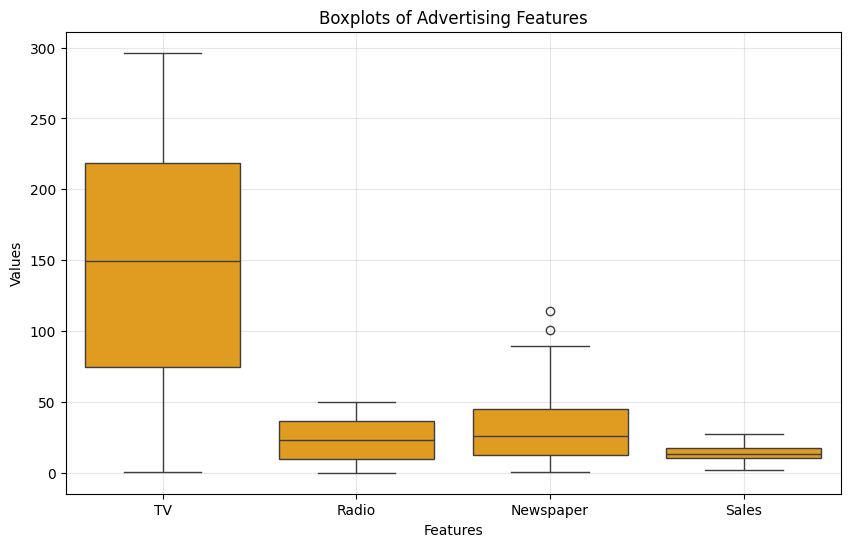

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, color="orange")

plt.title("Boxplots of Advertising Features")
plt.xlabel("Features")
plt.ylabel("Values")
plt.grid(alpha=0.3)

plt.show()

## Correlation Heatmap

The correlation heatmap shows the strength and direction of relationships between the advertising channels and sales. Values closer to 1 indicate a strong positive relationship, while values closer to -1 indicate a strong negative relationship.

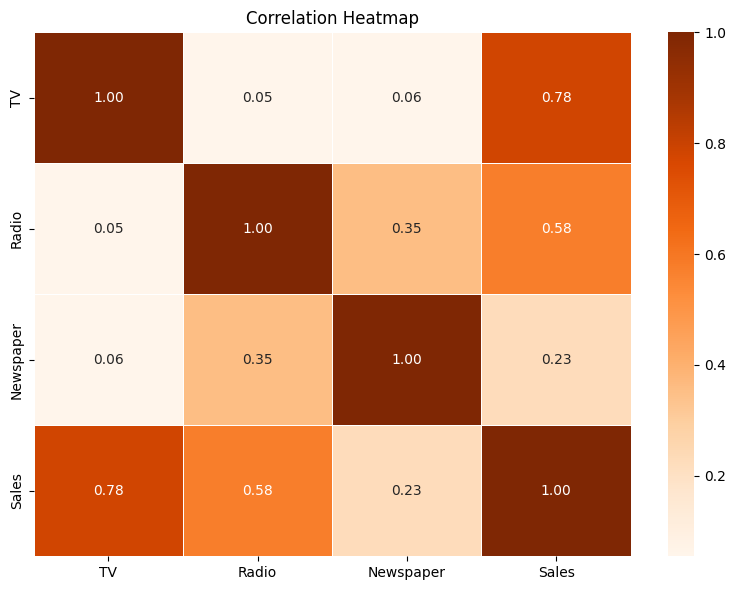

In [ ]:
plt.figure(figsize=(8, 6))

corr = df.corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="Oranges",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Feature Importance / Correlation with Sales

This analysis examines how strongly each advertising feature is related to product sales. Higher positive correlation values indicate that increases in the corresponding advertising channel are associated with higher sales.

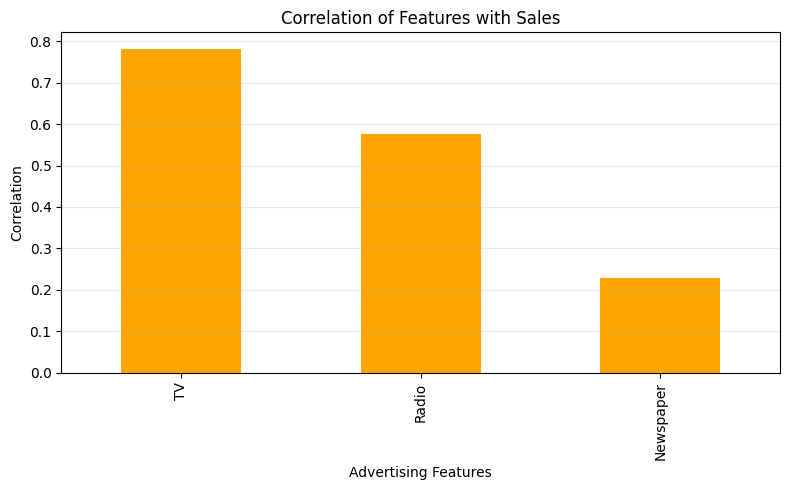

In [ ]:
plt.figure(figsize=(8, 5))

corr = df.corr()["Sales"].sort_values(ascending=False)

corr.drop("Sales").plot(kind="bar", color="orange")

plt.title("Correlation of Features with Sales")
plt.xlabel("Advertising Features")
plt.ylabel("Correlation")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Pair Plot

The pair plot provides a visual overview of the relationships and distributions among the advertising features and sales. It helps identify patterns, trends, and possible relationships between variables.

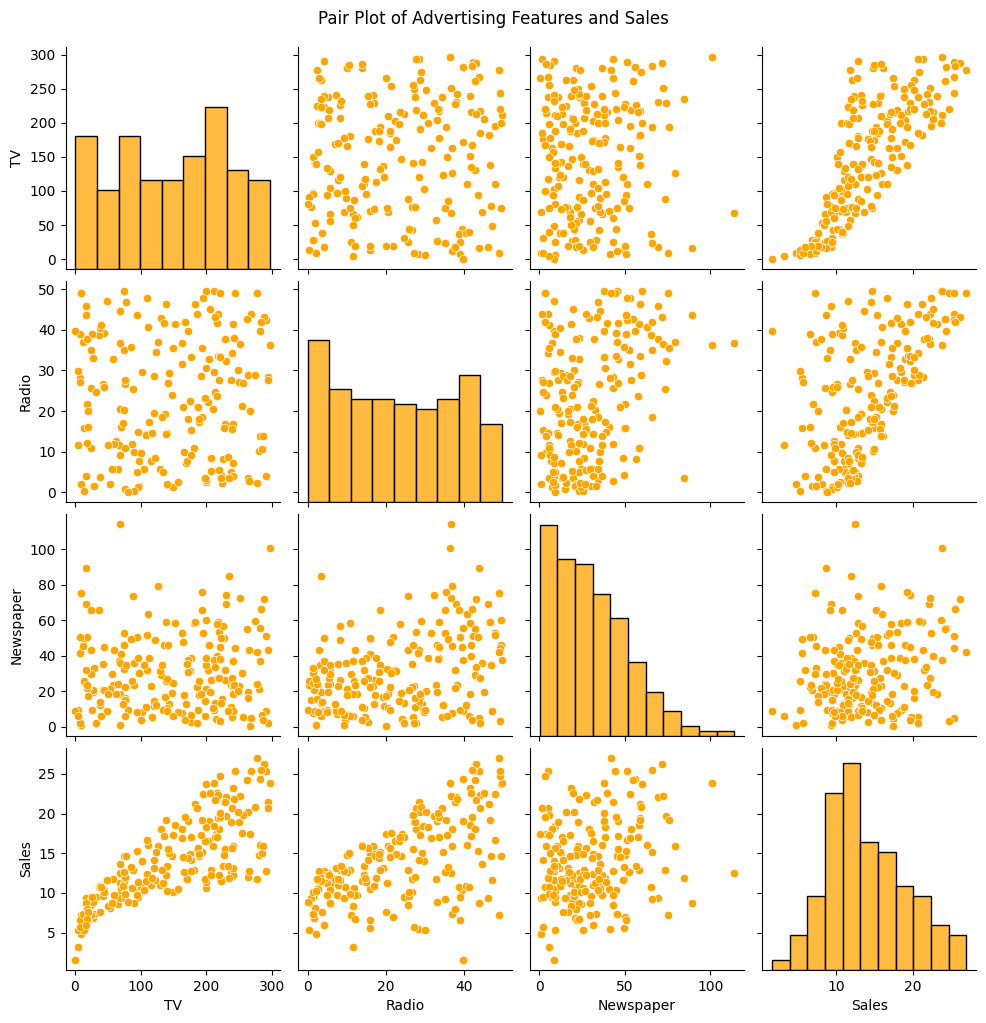

In [ ]:
sns.pairplot(
    df,
    diag_kind="hist",
    plot_kws={"color": "orange"},
    diag_kws={"color": "orange"}
)

plt.suptitle("Pair Plot of Advertising Features and Sales", y=1.02)
plt.show()

# 4. Data Preprocessing

## Feature Selection

The input features are separated from the target variable. TV, Radio, and Newspaper advertising budgets are used as predictors, while Sales is the target variable to be predicted.

In [ ]:
x = df.drop("Sales", axis=1)
y = df["Sales"]

print(x.head())
print(y.head())

      TV  Radio  Newspaper
0  230.1   37.8       69.2
1   44.5   39.3       45.1
2   17.2   45.9       69.3
3  151.5   41.3       58.5
4  180.8   10.8       58.4
0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: Sales, dtype: float64


## Split Dataset into Training and Testing Sets

The dataset is divided into training and testing sets to evaluate the performance of the machine learning model. 80% of the data is used for training, while the remaining 20% is reserved for testing.

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print("X_train shape :", x_train.shape)
print("X_test shape  :", x_test.shape)
print("Y_train shape :", y_train.shape)
print("Y_test shape  :", y_test.shape)

X_train shape : (160, 3)
X_test shape  : (40, 3)
Y_train shape : (160,)
Y_test shape  : (40,)


# 5. Machine Learning Models

## Linear Regression

Linear Regression is used to model the relationship between the advertising features and sales. The model is trained on the training dataset and then used to predict sales for the test dataset.

In [ ]:
lr_model = LinearRegression()

lr_model.fit(x_train, y_train)

lr_predictions = lr_model.predict(x_test)

print("Linear Regression model trained successfully")

Linear Regression model trained successfully


## Decision Tree Regressor

A Decision Tree Regressor is trained on the training dataset and used to predict sales on the testing dataset.

In [ ]:
dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(x_train, y_train)

dt_predictions = dt_model.predict(x_test)

print("Decision Tree Regressor trained successfully!")

Decision Tree Regressor trained successfully!


## Random Forest Regressor

A Random Forest Regressor is trained on the training dataset and used to predict sales on the testing dataset. It combines multiple decision trees to produce accurate and robust predictions.

In [ ]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(x_train, y_train)

rf_predictions = rf_model.predict(x_test)

print("Random Forest Regressor trained successfully!")

Random Forest Regressor trained successfully!


## Sales Predictions from All Models

The trained models are used to generate sales predictions for the test dataset. The first five predictions from each model are displayed for comparison.

In [ ]:
print("Linear Regression Predictions:")
print(lr_predictions[:7])

print()

print("Decision Tree Predictions:")
print(dt_predictions[:7])

print()

print("Random Forest Predictions:")
print(rf_predictions[:7])

Linear Regression Predictions:
[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192]

Decision Tree Predictions:
[18.5 20.7 20.2  6.6 23.8 13.3 22.6]

Random Forest Predictions:
[17.698 21.804 20.628  6.793 22.927 13.379 22.376]


# 6. Model Evalution

In [ ]:
# Linear Refression Metrics
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_mse = mean_squared_error(y_test, lr_predictions)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression")
print("MAE :", lr_mae)
print("MSE :", lr_mse)
print("RMSE:", lr_rmse)
print("R² Score:", lr_r2)

Linear Regression
MAE : 1.4607567168117603
MSE : 3.1740973539761033
RMSE: 1.78159966153345
R² Score: 0.899438024100912


In [ ]:
# Decision Tree Metrics
dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_mse = mean_squared_error(y_test, dt_predictions)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Regressor")
print("MAE :", dt_mae)
print("MSE :", dt_mse)
print("RMSE:", dt_rmse)
print("R² Score:", dt_r2)

Decision Tree Regressor
MAE : 0.9850000000000001
MSE : 2.175
RMSE: 1.4747881203752624
R² Score: 0.9310914968293178


In [ ]:
# Random Forest Metrics
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Regressor")
print("MAE :", rf_mae)
print("MSE :", rf_mse)
print("RMSE:", rf_rmse)
print("R² Score:", rf_r2)

Random Forest Regressor
MAE : 0.6200999999999988
MSE : 0.5907322499999988
RMSE: 0.7685910811348248
R² Score: 0.9812843792541843


# 6. Model Evaluation

The trained models are evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² Score.

In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        lr_mae,
        dt_mae,
        rf_mae
    ],
    "MSE": [
        lr_mse,
        dt_mse,
        rf_mse
    ],
    "RMSE": [
        lr_rmse,
        dt_rmse,
        rf_rmse
    ],
    "R2 Score": [
        lr_r2,
        dt_r2,
        rf_r2
    ]
})

comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.460757,3.174097,1.781600,0.899438
1,Decision Tree,0.985000,2.175000,1.474788,0.931091
2,Random Forest,0.620100,0.590732,0.768591,0.981284


# Observation

The model comparison shows that the Random Forest Regressor provides the best overall performance based on the evaluation metrics. It achieves a high R² Score while maintaining relatively low MAE, MSE, and RMSE, making it the most suitable model for sales prediction in this dataset.

# 7. Sales Prediction

### Prediction Example 1

Let's predict sales for a new advertising budget using the trained Random Forest Regressor.

In [ ]:
new_data = pd.DataFrame({
    "TV": [180],
    "Radio": [58],
    "Newspaper": [12]
})

prediction = rf_model.predict(new_data)

print(f"Predicted Sales: {prediction[0]:.2f}")

Predicted Sales: 20.76


### Prediction Example 2

Let's make another sales prediction using a different advertising budget.

In [ ]:
new_data2 = pd.DataFrame({
    "TV": [230],
    "Radio": [35],
    "Newspaper": [20]
})

prediction2 = rf_model.predict(new_data2)

print(f"Predicted Sales: {prediction2[0]:.2f}")

Predicted Sales: 20.89


## Observation

The Random Forest Regressor successfully predicted sales for two different advertising budgets. The model predicted 20.76 for Example 1 and 20.89 for Example 2, demonstrating its ability to estimate sales for new advertising inputs.

# 8. Conclusion

The Sales Prediction project successfully demonstrated how machine learning models can be used to predict sales based on advertising expenditure. Linear Regression, Decision Tree Regressor, and Random Forest Regressor were trained and evaluated using standard performance metrics. The models were also used to generate sales predictions for new advertising budgets. Overall, this project shows how data analysis and machine learning can support better sales forecasting and advertising decisions.